# 🍄 Mushroom Classification: Edible or Poisonous?

## 1. The Idea

**What does the model predict?**
Given a mushroom's physical characteristics (cap shape, cap colour, odour, gill size, spore print colour, habitat, …),
the model predicts whether the mushroom is **edible (`e`)** or **poisonous (`p`)**.

**Why is it useful?**
- Foragers, hikers and hobbyists can mistake poisonous mushrooms for edible ones, sometimes with fatal results.
- A classifier built on easy-to-observe features shows *which* characteristics matter most (for example, smell), which is useful knowledge on its own.
- It's a good beginner project: the dataset is clean and fully categorical, and the target is binary, so we can focus on the machine-learning workflow itself.

> ⚠️ **Disclaimer:** This is a learning exercise. Never eat a wild mushroom based on a model's prediction. Always ask a qualified expert.

**Dataset:** [UCI Mushroom Dataset](https://archive.ics.uci.edu/dataset/73/mushroom): 8,124 samples of 23 species of gilled mushrooms (Agaricus and Lepiota family), 22 categorical features + 1 target.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## 2. Data Preparation

### 2.1 Load the dataset

In [2]:
df = pd.read_csv("data/mushrooms.csv")
print("Shape:", df.shape)
df.head()

Shape: (8124, 23)


,type,cap_shape,cap_surface,cap_color,bruises,odor,gill_attachment,gill_spacing,gill_size,gill_color,...,stalk_surface_below_ring,stalk_color_above_ring,stalk_color_below_ring,veil_type,veil_color,ring_number,ring_type,spore_print_color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   type                      8124 non-null   str  
 1   cap_shape                 8124 non-null   str  
 2   cap_surface               8124 non-null   str  
 3   cap_color                 8124 non-null   str  
 4   bruises                   8124 non-null   str  
 5   odor                      8124 non-null   str  
 6   gill_attachment           8124 non-null   str  
 7   gill_spacing              8124 non-null   str  
 8   gill_size                 8124 non-null   str  
 9   gill_color                8124 non-null   str  
 10  stalk_shape               8124 non-null   str  
 11  stalk_root                8124 non-null   str  
 12  stalk_surface_above_ring  8124 non-null   str  
 13  stalk_surface_below_ring  8124 non-null   str  
 14  stalk_color_above_ring    8124 non-null   str  
 15

### 2.2 Check the target balance

type
edible       4208
poisonous    3916
Name: count, dtype: int64


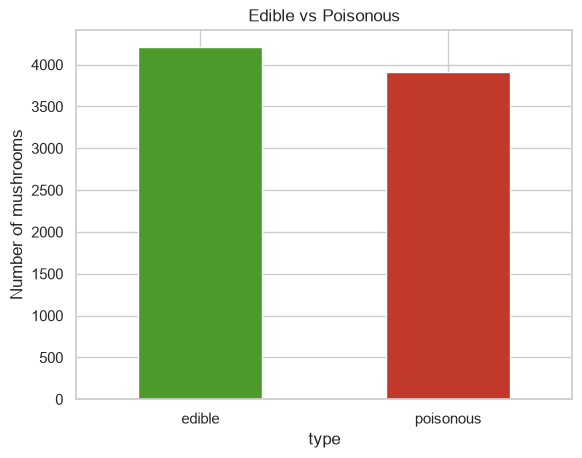

In [4]:
counts = df["type"].value_counts().rename({"e": "edible", "p": "poisonous"})
print(counts)
counts.plot(kind="bar", color=["#4C9A2A", "#C0392B"], rot=0, title="Edible vs Poisonous")
plt.ylabel("Number of mushrooms")
plt.show()

The classes are roughly balanced (~52% edible / ~48% poisonous), so **accuracy** is a fair metric here.

### 2.3 Check for missing values
Pandas reports no `NaN` values, but in this dataset missing values are stored as the character **`?`**, so we check for both.

In [5]:
print("NaN values per column (non-zero only):")
print(df.isna().sum()[lambda s: s > 0])

print("\n'?' values per column (non-zero only):")
print((df == "?").sum()[lambda s: s > 0])

NaN values per column (non-zero only):
Series([], dtype: int64)

'?' values per column (non-zero only):
stalk_root    2480
dtype: int64


Only **`stalk_root`** has missing values (2,480 rows, ~30%). Dropping those rows would throw away a lot of data,
so we treat `?` as its own category, **`missing`**. One-hot encoding will then turn it into its own column.

In [6]:
df["stalk_root"] = df["stalk_root"].replace("?", "missing")
print(df["stalk_root"].value_counts())

stalk_root
b          3776
missing    2480
e          1120
c           556
r           192
Name: count, dtype: int64


### 2.4 Remove useless features
A column with only one unique value gives the model no information.

In [7]:
print(df.nunique().sort_values().head())
constant_cols = [c for c in df.columns if df[c].nunique() == 1]
print("\nDropping constant columns:", constant_cols)
df = df.drop(columns=constant_cols)

veil_type          1
type               2
gill_attachment    2
gill_spacing       2
stalk_shape        2
dtype: int64

Dropping constant columns: ['veil_type']


### 2.5 Prepare features (X) and target (y)
- **Target:** `type` → encoded as `0 = edible`, `1 = poisonous`.
- **Features:** all other columns are categorical letters, so we **one-hot encode** them (each category becomes a 0/1 column).
  One-hot encoding matters for KNN because it measures distances, and arbitrary integer labels (a=0, b=1, c=2…) would create fake "distances" between categories.

In [8]:
X_raw = df.drop(columns="type")
y = LabelEncoder().fit_transform(df["type"])   # e -> 0, p -> 1
class_names = ["edible", "poisonous"]

encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
X = encoder.fit_transform(X_raw)
feature_names = encoder.get_feature_names_out(X_raw.columns)

print("Features before encoding:", X_raw.shape[1])
print("Features after one-hot encoding:", X.shape[1])

Features before encoding: 21
Features after one-hot encoding: 116


### 2.6 Train / test split (80% / 20%, stratified)

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (6499, 116)  Test: (1625, 116)


## 3. Model Building

### Model 1: Decision Tree
A Decision Tree learns a sequence of yes/no questions (e.g. *"Does it smell of almonds?"*). It's easy to read and needs no feature scaling.

In [10]:
dt = DecisionTreeClassifier(random_state=RANDOM_STATE)
dt.fit(X_train, y_train)
dt_pred = dt.predict(X_test)
print("Tree depth:", dt.get_depth(), "| Leaves:", dt.get_n_leaves())

Tree depth: 7 | Leaves: 14


### Model 2: K-Nearest Neighbors (KNN)
KNN labels a new mushroom by looking at the **k** most similar mushrooms in the training set and taking a majority vote.
We first pick a good value of *k* with 5-fold cross-validation on the training data.

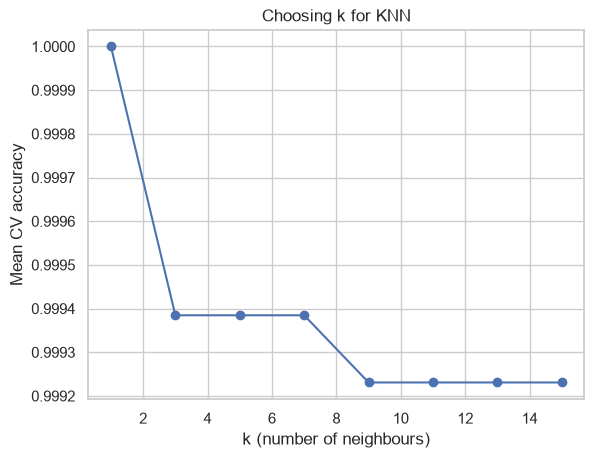

CV accuracy per k: {1: 1.0, 3: 0.9994, 5: 0.9994, 7: 0.9994, 9: 0.9992, 11: 0.9992, 13: 0.9992, 15: 0.9992}
Best k: 1


In [11]:
k_values = range(1, 16, 2)
cv_scores = [cross_val_score(KNeighborsClassifier(n_neighbors=k), X_train, y_train, cv=5).mean() for k in k_values]

plt.plot(list(k_values), cv_scores, marker="o")
plt.xlabel("k (number of neighbours)")
plt.ylabel("Mean CV accuracy")
plt.title("Choosing k for KNN")
plt.show()

# If several k values tie, take the largest one: more neighbours = smoother, less noise-sensitive model
best_score = max(cv_scores)
best_k = max(k for k, s in zip(k_values, cv_scores) if np.isclose(s, best_score))
print("CV accuracy per k:", {k: round(float(s), 4) for k, s in zip(k_values, cv_scores)})
print("Best k:", best_k)

In [12]:
knn = KNeighborsClassifier(n_neighbors=best_k)
knn.fit(X_train, y_train)
knn_pred = knn.predict(X_test)

## 4. Evaluation

### 4.1 Accuracy

In [13]:
results = pd.DataFrame({
    "Model": ["Decision Tree", f"KNN (k={best_k})"],
    "Test accuracy": [accuracy_score(y_test, dt_pred), accuracy_score(y_test, knn_pred)],
    "5-fold CV accuracy (train)": [
        cross_val_score(DecisionTreeClassifier(random_state=RANDOM_STATE), X_train, y_train, cv=5).mean(),
        cross_val_score(KNeighborsClassifier(n_neighbors=best_k), X_train, y_train, cv=5).mean(),
    ],
})
print(results.round(4).to_string(index=False))

        Model  Test accuracy  5-fold CV accuracy (train)
Decision Tree            1.0                      0.9997
    KNN (k=1)            1.0                      1.0000


### 4.2 Confusion matrices

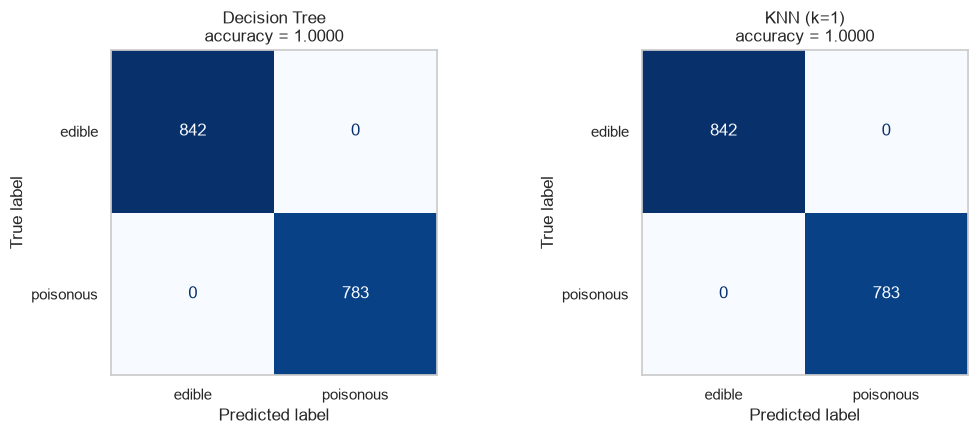

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, pred) in zip(axes, [("Decision Tree", dt_pred), (f"KNN (k={best_k})", knn_pred)]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=class_names).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.grid(False)
    ax.set_title(f"{name}\naccuracy = {accuracy_score(y_test, pred):.4f}")
plt.tight_layout()
plt.savefig("images/confusion_matrices.png", dpi=120, bbox_inches="tight")
plt.show()

In [15]:
print("Decision Tree\n", classification_report(y_test, dt_pred, target_names=class_names, digits=4))
print(f"KNN (k={best_k})\n", classification_report(y_test, knn_pred, target_names=class_names, digits=4))

Decision Tree
               precision    recall  f1-score   support

      edible     1.0000    1.0000    1.0000       842
   poisonous     1.0000    1.0000    1.0000       783

    accuracy                         1.0000      1625
   macro avg     1.0000    1.0000    1.0000      1625
weighted avg     1.0000    1.0000    1.0000      1625

KNN (k=1)
               precision    recall  f1-score   support

      edible     1.0000    1.0000    1.0000       842
   poisonous     1.0000    1.0000    1.0000       783

    accuracy                         1.0000      1625
   macro avg     1.0000    1.0000    1.0000      1625
weighted avg     1.0000    1.0000    1.0000      1625



### 4.3 A harder test: what if we only used a *tiny* tree?
Both models are near-perfect on this dataset. To see which features carry the most information,
we train a Decision Tree limited to **depth 3** (at most 3 questions) and look at it.

Depth-3 tree test accuracy: 0.9822


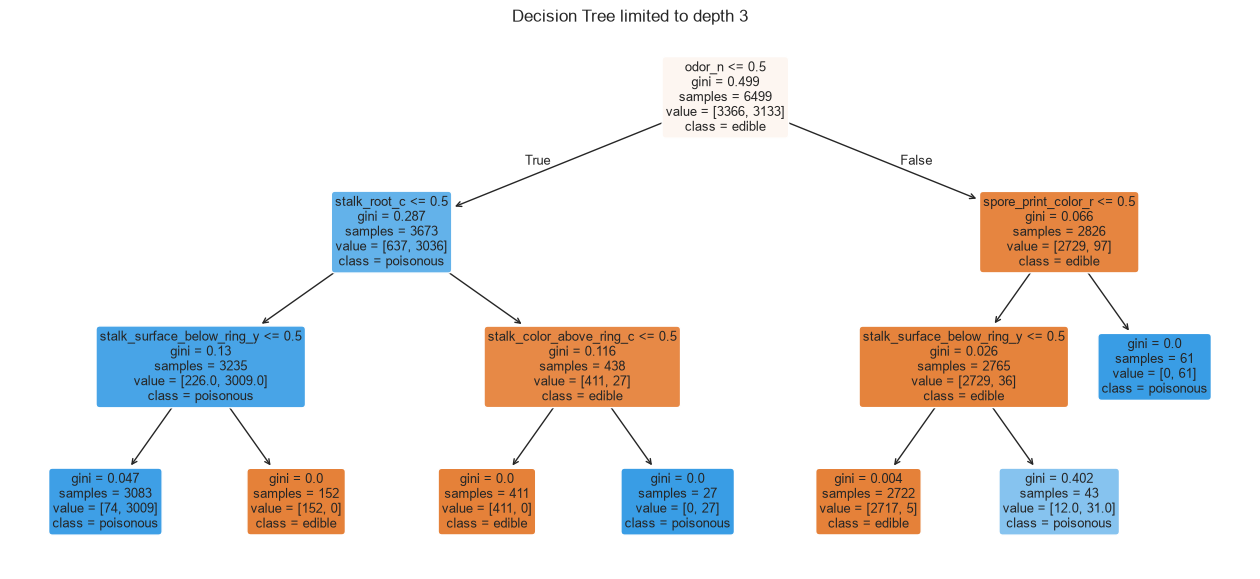

In [16]:
dt_small = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE).fit(X_train, y_train)
print("Depth-3 tree test accuracy:", round(accuracy_score(y_test, dt_small.predict(X_test)), 4))

plt.figure(figsize=(16, 7))
plot_tree(dt_small, feature_names=feature_names, class_names=class_names, filled=True, rounded=True, fontsize=9)
plt.title("Decision Tree limited to depth 3")
plt.show()

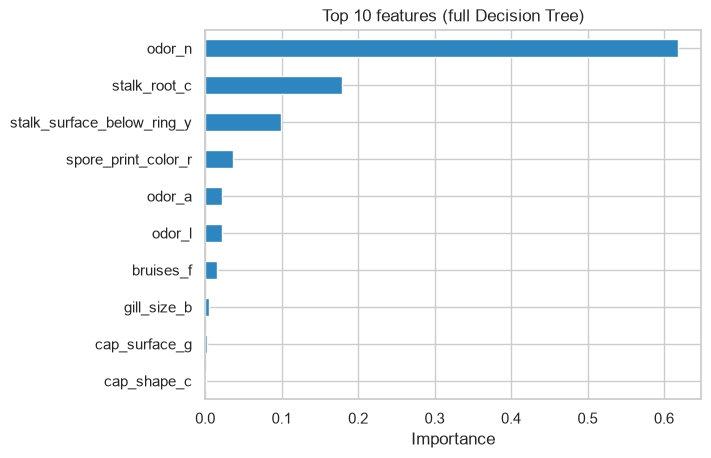

In [17]:
importances = pd.Series(dt.feature_importances_, index=feature_names).sort_values(ascending=False).head(10)
importances[::-1].plot(kind="barh", color="#2E86C1", title="Top 10 features (full Decision Tree)")
plt.xlabel("Importance")
plt.savefig("images/feature_importance.png", dpi=120, bbox_inches="tight")
plt.show()

## 5. Conclusion

**Which model performed better?**
| Model | Test accuracy | 5-fold CV accuracy |
|---|---|---|
| Decision Tree | 100.00% | 99.97% |
| KNN (k = 1) | 100.00% | 100.00% |

- Both models reach **100% test accuracy**, with **zero** poisonous mushrooms predicted as edible and zero edible mushrooms predicted as poisonous.
- In cross-validation **KNN is marginally better** (100% vs 99.97%, a difference of about 2 mushrooms out of 6,499), so on accuracy alone KNN wins by a hair. For practical purposes the two are tied.
- I would still choose the **Decision Tree** for this problem because:
  1. It is **interpretable**: we can read off the rules (the very first question it asks is *"does the mushroom have no smell?"*), which matters when a wrong answer is dangerous.
  2. It is **faster at prediction time**: KNN has to compare each new mushroom to all ~6,500 training mushrooms.
  3. It needs no tuning of *k* and no distance metric.

**What I learned**
- **Missing values aren't always `NaN`.** This dataset hides them as `?`, so it's worth checking the raw values.
- **Encoding matters.** Categorical letters must be converted to numbers. One-hot encoding avoids inventing a fake order, which is especially important for distance-based models like KNN.
- **Remove useless columns.** `veil_type` has one value and adds nothing.
- **Odour is the strongest single clue.** `odor_n` (no smell) alone accounts for ~62% of the full tree's feature importance, and a tree that asks only 3 questions already reaches ~98% accuracy.
- **Perfect accuracy should make you suspicious.** Here it's real (the dataset is very separable), but in a safety-critical task, the number of *poisonous mushrooms predicted as edible* (false negatives) matters more than overall accuracy.